# Evaporator production system: DES and Monte Carlo walkthrough

> **Illustrative, anonymised data** ("the Company"). This is not measured company data.

The notebook reads the committed result files in `results/` (produced by `make all`), re-evaluates
the analytical equations, and runs one deterministic and one stochastic replication live. Every
number shown is computed from the files or the code, so the notebook cannot drift from the results.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

from evapsim import equations as eq
from evapsim import plots
from evapsim.config import apply_overrides, load_config
from evapsim.model import simulate

plots.apply_style()
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)
RES, FIG = ROOT / "results", ROOT / "results" / "figures"
cfg = load_config()
print(f"takt {cfg.takt_min:.0f} min/EVA at {cfg.demand:g} EVA/week; lot {cfg.lot}, "
      f"transfer batch {cfg.transfer_batch}")

takt 800 min/EVA at 3 EVA/week; lot 3, transfer batch 3


## 1. Analytical model: fin press (equations A1-A8) and resource loads

In [2]:
fp = eq.fin_press(**cfg.fin_press)
print(f"T_run {fp.T_run:.2f} min/EVA | T_eva {fp.T_eva:.2f} | T_job {fp.T_job:.2f} min per {cfg.lot} EVA"
      f" (whiteboard 229) | OEE {fp.OEE:.4f} = A_tot*P*Q = {fp.OEE_check:.4f} | r_eff {fp.r_eff:.1f} fins/min")
print("A8 calibration: F =", round(eq.calibrate_good_fins(0.70, 75, 229, 3), 1))
pd.read_csv(RES / "fin_press_oee_options.csv").round(4)

T_run 57.29 min/EVA | T_eva 66.20 | T_job 228.61 min per 3 EVA (whiteboard 229) | OEE 0.6999 = A_tot*P*Q = 0.6999 | r_eff 52.5 fins/min
A8 calibration: F = 4007.5


,case,S,P,Q,MTBF,MTTR,t_r,T_job_min,min_per_eva,A_u,A_tot,OEE
0,baseline (calibrated),30.0,0.950,0.98,270.0,30.0,5.0,228.6066,76.2022,0.9000,0.7518,0.6999
1,SMED only: setup -40%,18.0,0.950,0.98,270.0,30.0,5.0,216.6066,72.2022,0.9000,0.7934,0.7387
2,"cap: setup -40%, A_u = P = 1",18.0,1.000,0.98,270.0,0.0,5.0,188.9184,62.9728,1.0000,0.8642,0.8469
3,S4 package (SMED + TPM + quick reel change),18.0,0.985,0.99,540.0,10.0,2.0,188.1461,62.7154,0.9818,0.8721,0.8504


In [3]:
eq.resource_loads(cfg)[["rank", "label", "min_per_eva", "capacity_eva_per_week",
                        "utilisation_at_demand", "utilisation_with_rework"]].round(3)

,rank,label,min_per_eva,capacity_eva_per_week,utilisation_at_demand,utilisation_with_rework
0,1,Steeking crew,420.000,5.714,0.525,0.525
1,2,Header welder,384.000,6.250,0.480,0.483
2,3,Hairpin welder,216.000,11.111,0.270,0.270
3,4,Fin press / boxing operator,176.202,13.621,0.220,0.220
4,5,Final assembly crew,150.000,16.000,0.188,0.188
5,6,Return-bend welder,144.000,16.667,0.180,0.180
6,7,Header preparation,120.000,20.000,0.150,0.150
7,8,Sheet-metal assembler,105.000,22.857,0.131,0.131
8,9,Drip-tray welder,100.000,24.000,0.125,0.125
9,10,Pressure-test bay,90.000,26.667,0.112,0.117


## 2. Hand calculation vs deterministic simulation (must match exactly)

In [4]:
det = apply_overrides(cfg, {"simulation": {"deterministic": True}})
cp = eq.deterministic_lead_time(det)
res = simulate(det)
lt = res.orders[res.orders.completed_in_window]["lead_time_min"]
print(f"critical path {cp['lead_time_min']:.1f} min = {cp['lead_time_days']:.2f} d | "
      f"simulated min/max {lt.min():.1f}/{lt.max():.1f}")
pd.read_csv(RES / "deterministic_check.csv").head(8)

critical path 10848.0 min = 22.60 d | simulated min/max 10848.0/10848.0


,case,quantity,hand_calc,simulated_min,simulated_max,max_abs_diff,exact_match
0,baseline (transfer batch 3),order lead time (min),10848.000000,10848.000000,10848.000000,0.000000e+00,True
1,baseline (transfer batch 3),utilisation steeking_crew,0.525000,0.525000,0.525000,0.000000e+00,True
2,baseline (transfer batch 3),utilisation header_welder,0.480000,0.480000,0.480000,0.000000e+00,True
3,baseline (transfer batch 3),utilisation hairpin_welder,0.270000,0.270000,0.270000,0.000000e+00,True
4,baseline (transfer batch 3),utilisation fin_press_operator,0.220253,0.220253,0.220253,2.470246e-15,True
5,baseline (transfer batch 3),utilisation assembly_crew,0.187500,0.187500,0.187500,0.000000e+00,True
6,baseline (transfer batch 3),utilisation return_bend_welder,0.180000,0.180000,0.180000,0.000000e+00,True
7,baseline (transfer batch 3),utilisation header_prep_operator,0.150000,0.150000,0.150000,0.000000e+00,True


## 3. One stochastic replication: an order's EVA through the coil route

Each bar is an operation on one EVA. Gaps are waiting: for material, for the other EVA in the transfer
batch, for joins, or in a queue.

In [5]:
r = simulate(cfg, rep=0)
ev = r.evas.dropna(subset=["completion"])
o = ev[ev.order == ev.order.iloc[10]]
ops = ["trim_tubes", "weld_hairpins", "boxing", "steeking", "weld_return_bends", "expansion",
       "header_welding", "wash", "pressure_test", "complete_assembly"]
fig, ax = plt.subplots(figsize=(11, 3.2))
for k, op in enumerate(ops):
    ax.barh([f"EVA {i}" for i in o.idx], (o[f"{op}_end"] - o[f"{op}_start"]) / 480,
            left=(o[f"{op}_start"] - o.arrival) / 480, color=plots.SERIES[k % 8], label=op, height=0.6)
ax.set_xlabel("Working days since order arrival")
ax.legend(ncol=5, fontsize=7, loc="lower center", bbox_to_anchor=(0.5, 1.02))
plt.show()
print("order lead time (d):", round((o.completion.max() - o.arrival.iloc[0]) / 480, 2))

order lead time (d): 23.0


## 4. Baseline Monte Carlo (S0, 3 EVA/week)

In [6]:
pd.read_csv(RES / "baseline_kpis.csv")[["label", "unit", "mean", "ci_low", "ci_high", "n"]].round(3)

,label,unit,mean,ci_low,ci_high,n
0,Throughput,EVA/week,2.992,2.979,3.004,300
1,Demand attainment,TH / demand,0.997,0.993,1.002,300
2,Weekly demand compliance,share of weeks,0.723,0.718,0.728,300
3,"Order lead time, mean",working days,23.123,23.074,23.171,300
4,"Order lead time, P50",working days,22.723,22.671,22.774,300
5,"Order lead time, P90",working days,26.765,26.658,26.871,300
6,"Order lead time, P95",working days,28.242,28.105,28.379,300
7,On-time delivery,share of orders,0.972,0.969,0.974,300
8,WIP in system,EVA,13.655,13.593,13.717,300
9,WIP from Little's law,EVA,13.650,13.584,13.715,300


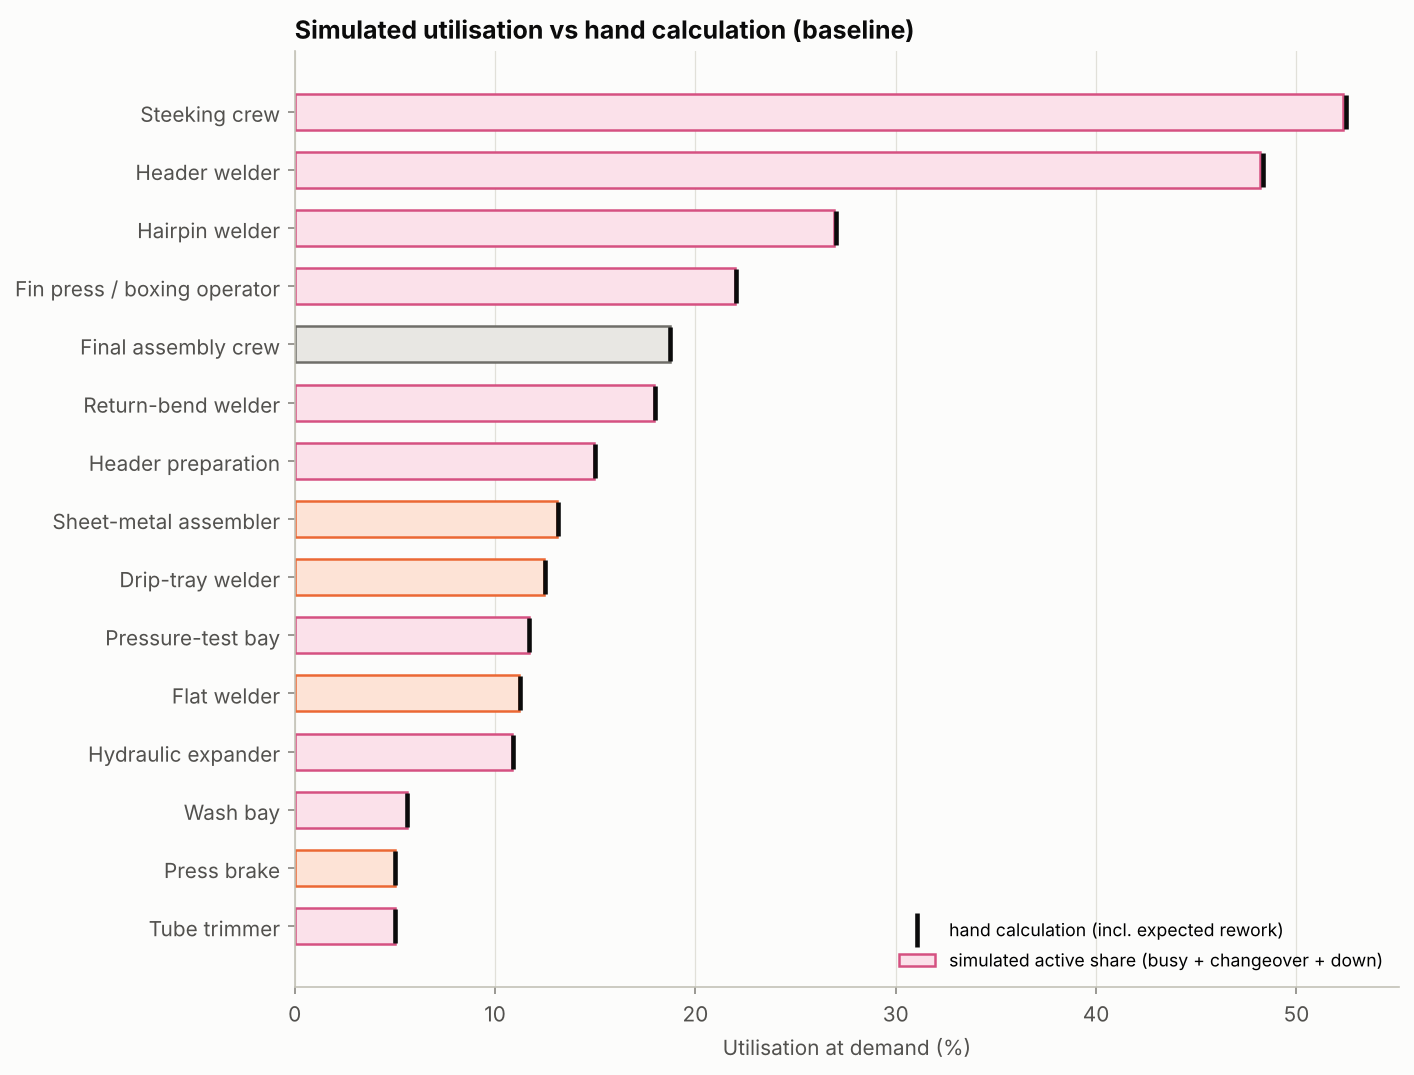

,resource,count,share,method
0,steeking_crew,300,1.0,highest active share
1,steeking_crew,300,1.0,longest mean queue


In [7]:
display(Image(filename=str(FIG / "baseline_utilisation_vs_handcalc.png"), width=800))
pd.read_csv(RES / "baseline_bottleneck_frequency.csv")

## 5. Validation and calibration

In [8]:
display(pd.read_csv(RES / "calibration_grid.csv").round(3))
pd.read_csv(RES / "validation_summary.csv").round(3)

,parameter,value,simulated_lt_mean_days,observed_lt_mean_days,error_pct,prediction_interval_p,passes,selected_min_change,best_fit
0,lead_times.procurement_tubing.mean_days,8.00,22.355,24.284,-7.944,0.020,False,False,False
1,lead_times.procurement_tubing.mean_days,8.25,22.620,24.284,-6.853,0.020,False,False,False
2,lead_times.procurement_tubing.mean_days,8.50,22.878,24.284,-5.790,0.033,False,False,False
3,lead_times.procurement_tubing.mean_days,8.75,23.142,24.284,-4.704,0.093,True,True,False
4,lead_times.procurement_tubing.mean_days,9.00,23.407,24.284,-3.610,0.233,True,False,False
5,lead_times.procurement_tubing.mean_days,9.25,23.668,24.284,-2.537,0.339,True,False,False
6,lead_times.procurement_tubing.mean_days,9.50,23.930,24.284,-1.460,0.618,True,False,False
7,lead_times.procurement_tubing.mean_days,9.75,24.186,24.284,-0.403,0.837,True,False,True
8,lead_times.procurement_tubing.mean_days,10.00,24.451,24.284,0.686,0.837,True,False,False
9,lead_times.procurement_tubing.mean_days,10.25,24.717,24.284,1.783,0.591,True,False,False


,measure,unit,observed_mean,n_observed,simulated_mean,sim_pi95_low,sim_pi95_high,error_pct,within_target,prediction_interval_p,welch_t_p,verdict
0,Mean weekly output,EVA/week,2.885,26,2.977,2.654,3.346,3.196,True,0.784,0.514,valid
1,Mean order lead time,working days,24.284,25,23.142,21.933,24.446,-4.704,True,0.093,0.104,valid


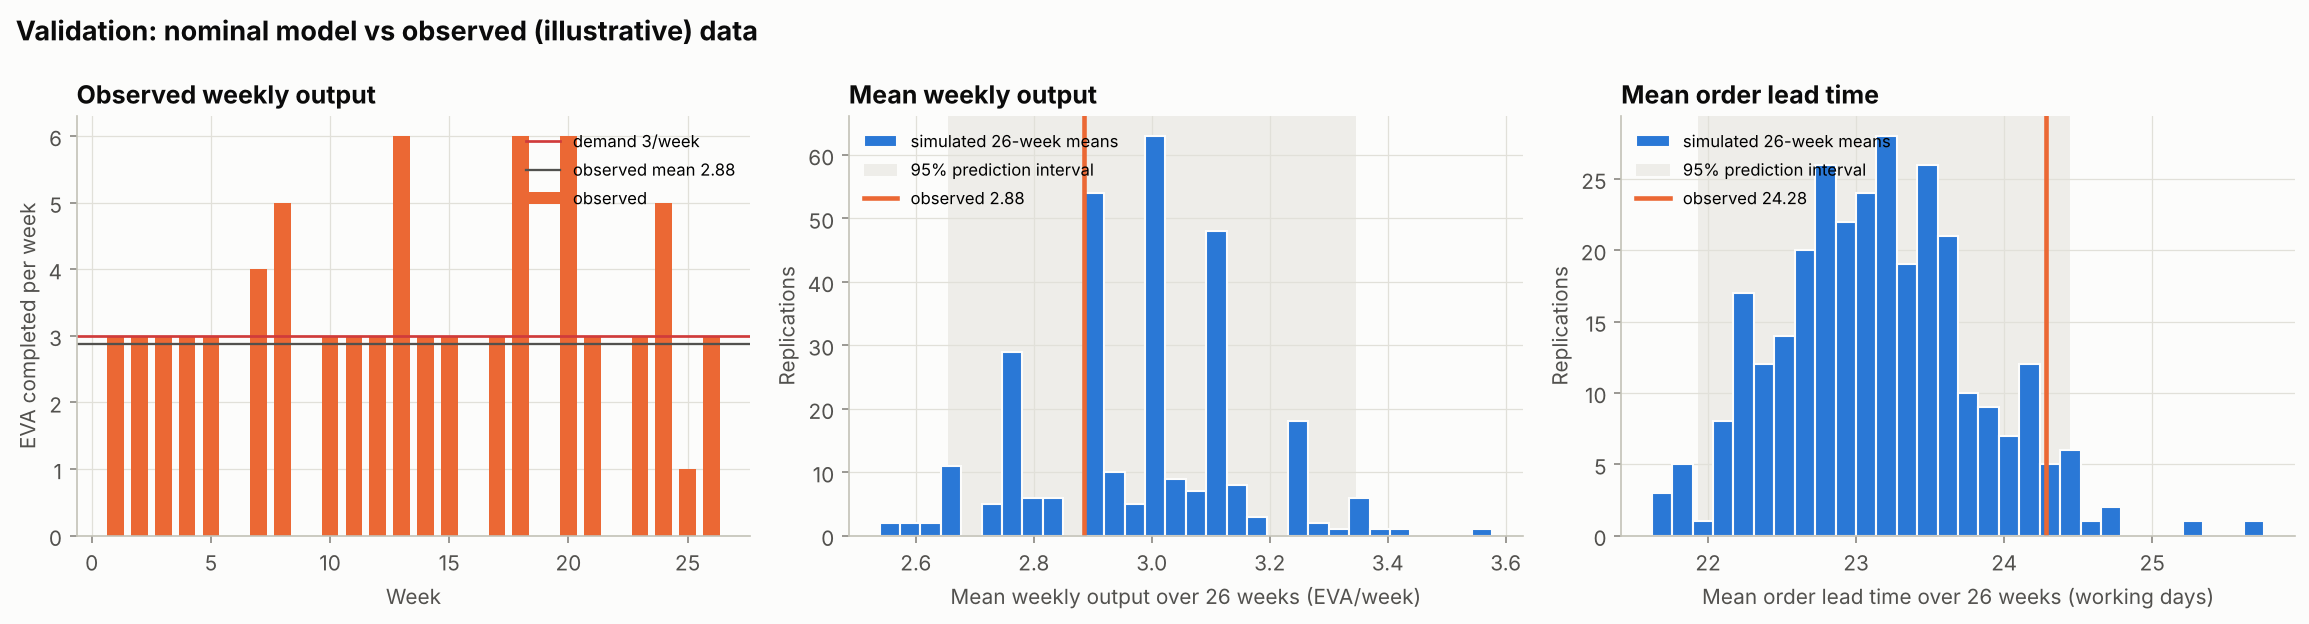

,demand_eva_per_week,station,rho_sim,ca2_measured,ca2_release,cs2_sim,t_e_lot_min,wq_sim_min,wq_kingman_measured_ca2_min,wq_kingman_release_ca2_min,bracketed,lots
0,3.0,steeking,0.525,0.369,0.062,0.015,1252.467,168.556,266.655,53.846,True,1562
1,3.0,header_welding,0.486,0.277,0.062,0.009,1151.746,16.247,155.687,38.911,False,1559
2,4.0,steeking,0.698,0.411,0.062,0.015,1251.600,352.521,616.774,112.561,True,2069
3,4.0,header_welding,0.647,0.228,0.062,0.010,1149.643,27.956,250.129,76.112,False,2075
4,5.0,steeking,0.872,0.410,0.062,0.015,1251.154,775.136,1805.323,328.711,True,2579
5,5.0,header_welding,0.805,0.111,0.062,0.010,1149.047,49.179,286.093,171.369,False,2593
6,5.5,steeking,0.956,0.401,0.062,0.015,1252.571,1602.392,5596.568,1043.155,True,2820
7,5.5,header_welding,0.881,0.050,0.062,0.009,1148.699,69.021,249.394,303.383,False,2835


In [9]:
display(Image(filename=str(FIG / "validation.png"), width=1000))
pd.read_csv(RES / "kingman_check.csv").round(3)

## 6. Input uncertainty about steeking (two-level Monte Carlo)

,demand_eva_per_week,metric,var_input,var_process,var_total,share_input,share_process,outer,inner,grand_mean
0,3.0,lt_mean_days,0.1987,0.1856,0.3843,0.5171,0.4829,40,10,23.5070
1,3.0,lt_p90_days,0.2087,1.0213,1.2300,0.1697,0.8303,40,10,27.1835
2,3.0,throughput_eva_week,0.0000,0.0124,0.0124,0.0000,1.0000,40,10,2.9908
3,5.0,lt_mean_days,34.2044,5.5054,39.7098,0.8614,0.1386,40,10,29.1450
4,5.0,lt_p90_days,74.3747,13.0225,87.3972,0.8510,0.1490,40,10,34.6757
5,5.0,throughput_eva_week,0.0404,0.0128,0.0532,0.7592,0.2408,40,10,4.8501


,steeking_hours_per_eva,steeking_min_per_eva,steeking_capacity_eva_week,demand_eva_per_week,throughput_eva_week,lt_mean_days,lt_p95_days,on_time,steeking_utilisation,eva_in_system_at_end,stable
0,6,360.0,6.667,3.0,2.999,22.635,27.678,0.979,0.449,13.48,True
1,7,420.0,5.714,3.0,3.002,23.083,28.155,0.974,0.523,13.70,True
2,16,960.0,2.500,3.0,2.502,50.812,69.733,0.043,0.999,43.33,False
3,20,1200.0,2.000,3.0,2.011,74.936,112.112,0.010,1.000,70.50,False


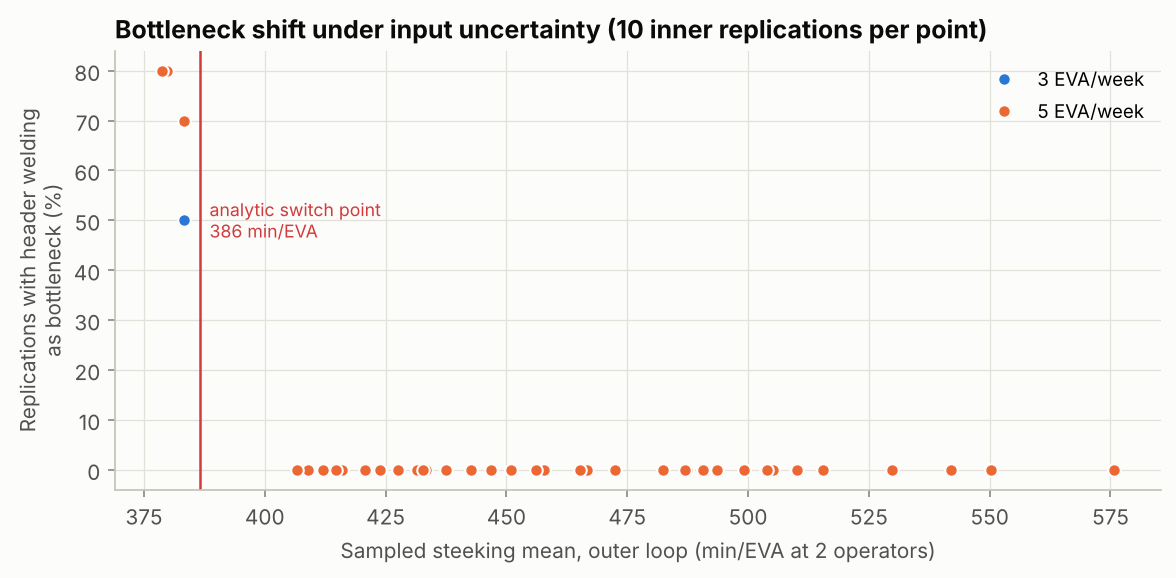

In [10]:
display(pd.read_csv(RES / "variance_decomposition.csv").round(4))
display(pd.read_csv(RES / "steeking_cases.csv").round(3))
display(Image(filename=str(FIG / "uncertainty_bottleneck.png"), width=800))

## 7. Scenarios, demand sweep and sensitivity

In [11]:
s = pd.read_csv(RES / "scenario_summary.csv")
s[["scenario", "name", "demand_eva_per_week", "throughput_eva_week_mean", "lt_mean_days_mean",
   "lt_p95_days_mean", "on_time_mean", "bottleneck", "steeking_util", "header_util"]].round(3)

,scenario,name,demand_eva_per_week,throughput_eva_week_mean,lt_mean_days_mean,lt_p95_days_mean,on_time_mean,bottleneck,steeking_util,header_util
0,S0,Baseline,3.0,2.992,23.123,28.242,0.972,steeking_crew,0.523,0.482
1,S1,3rd steeking operator,3.0,2.992,22.466,27.551,0.980,header_welder,0.411,0.482
2,S2,Steeking standard work / fixtures,3.0,2.992,22.509,27.591,0.980,header_welder,0.419,0.482
3,S3,2nd header-welding station,3.0,2.992,22.217,27.330,0.982,steeking_crew,0.523,0.241
4,S4,Fin press OEE 70% -> 85%,3.0,2.992,23.123,28.242,0.972,steeking_crew,0.523,0.482
5,S5,One-piece flow (transfer batch 1),3.0,2.990,18.641,23.754,0.997,steeking_crew,0.524,0.482
6,S6,Combined: S1 + S3 + CONWIP,3.0,2.991,21.495,26.525,0.989,steeking_crew,0.411,0.241
7,S7,Recommended: S6 + one-piece flow,3.0,2.989,17.878,22.857,0.998,steeking_crew,0.411,0.241
8,S0,Baseline,5.0,4.979,24.722,30.099,0.942,steeking_crew,0.871,0.803
9,S1,3rd steeking operator,5.0,4.984,23.497,28.766,0.967,header_welder,0.684,0.803


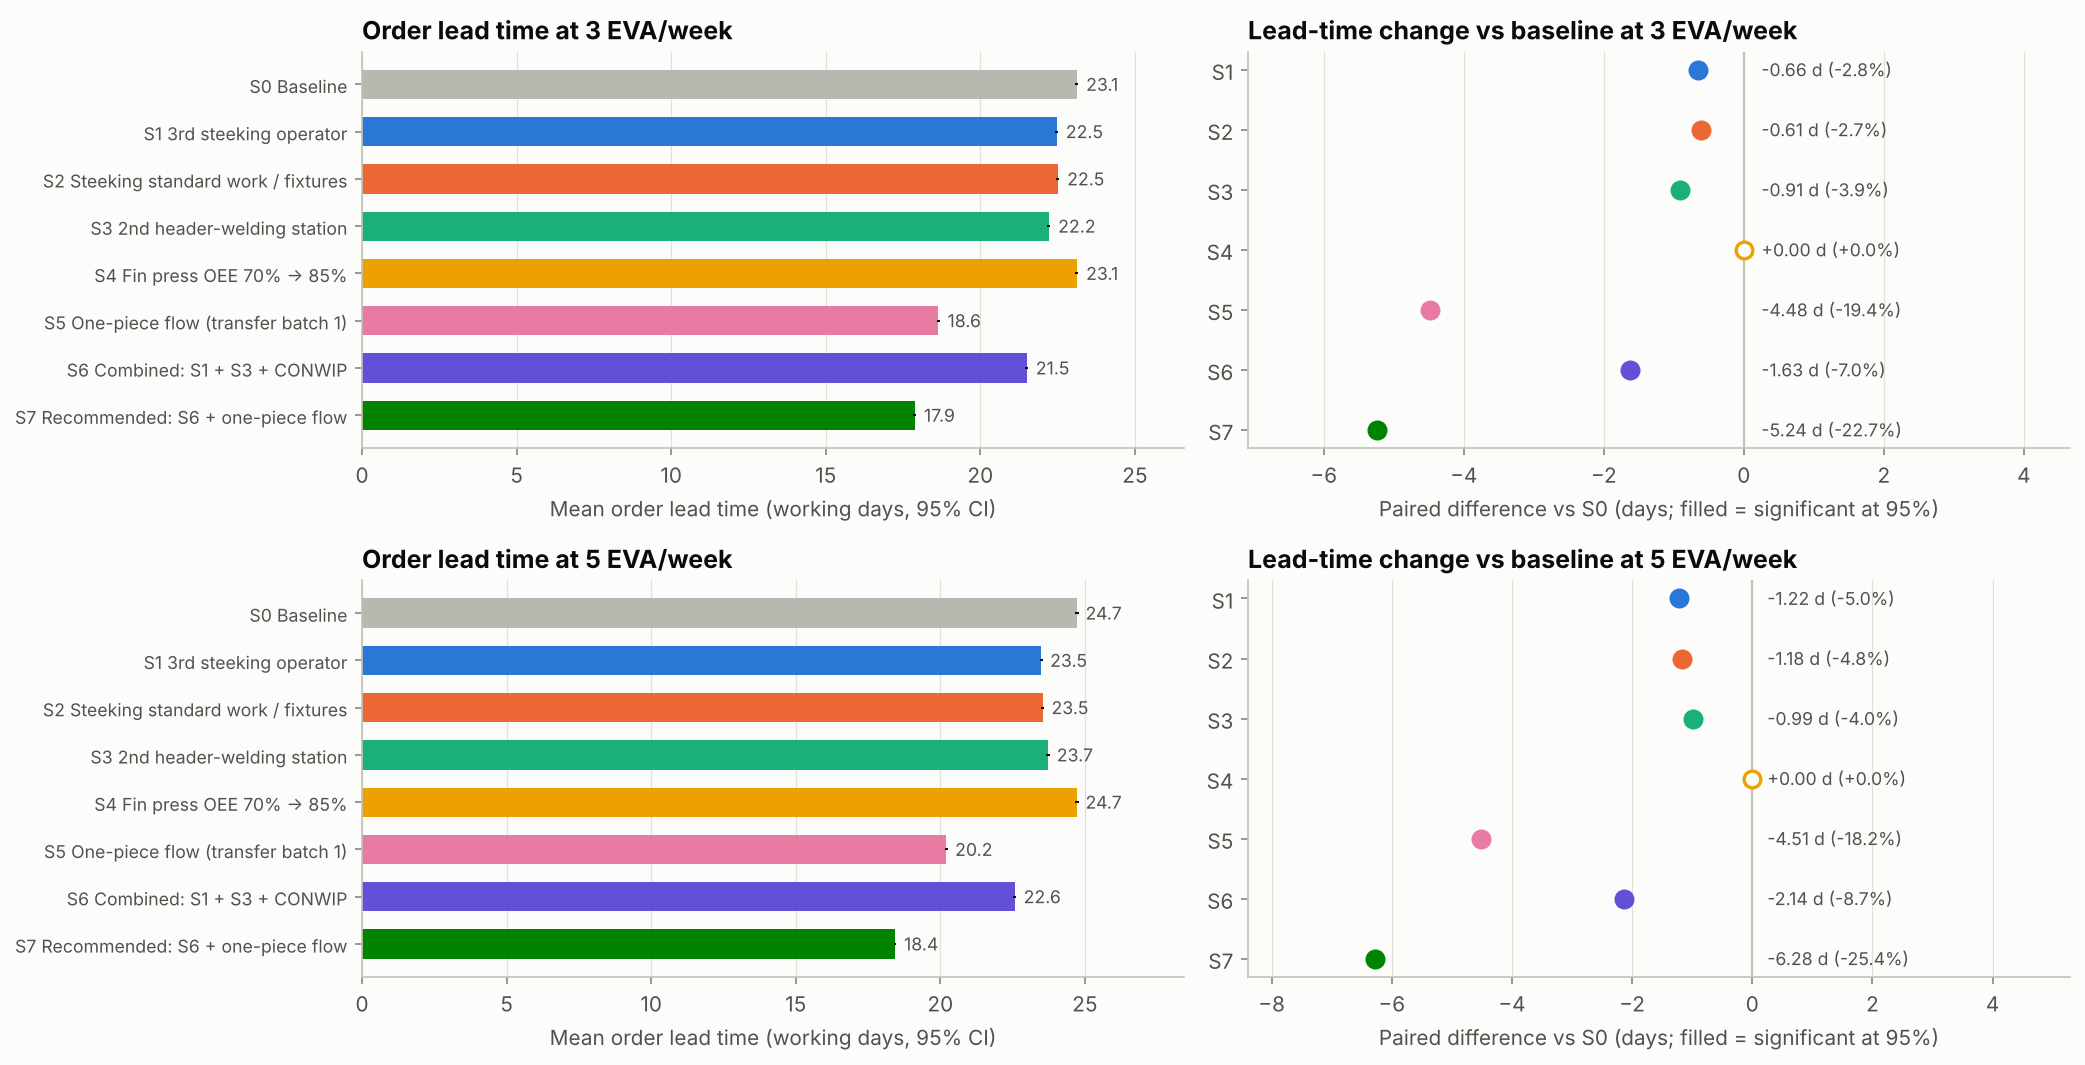

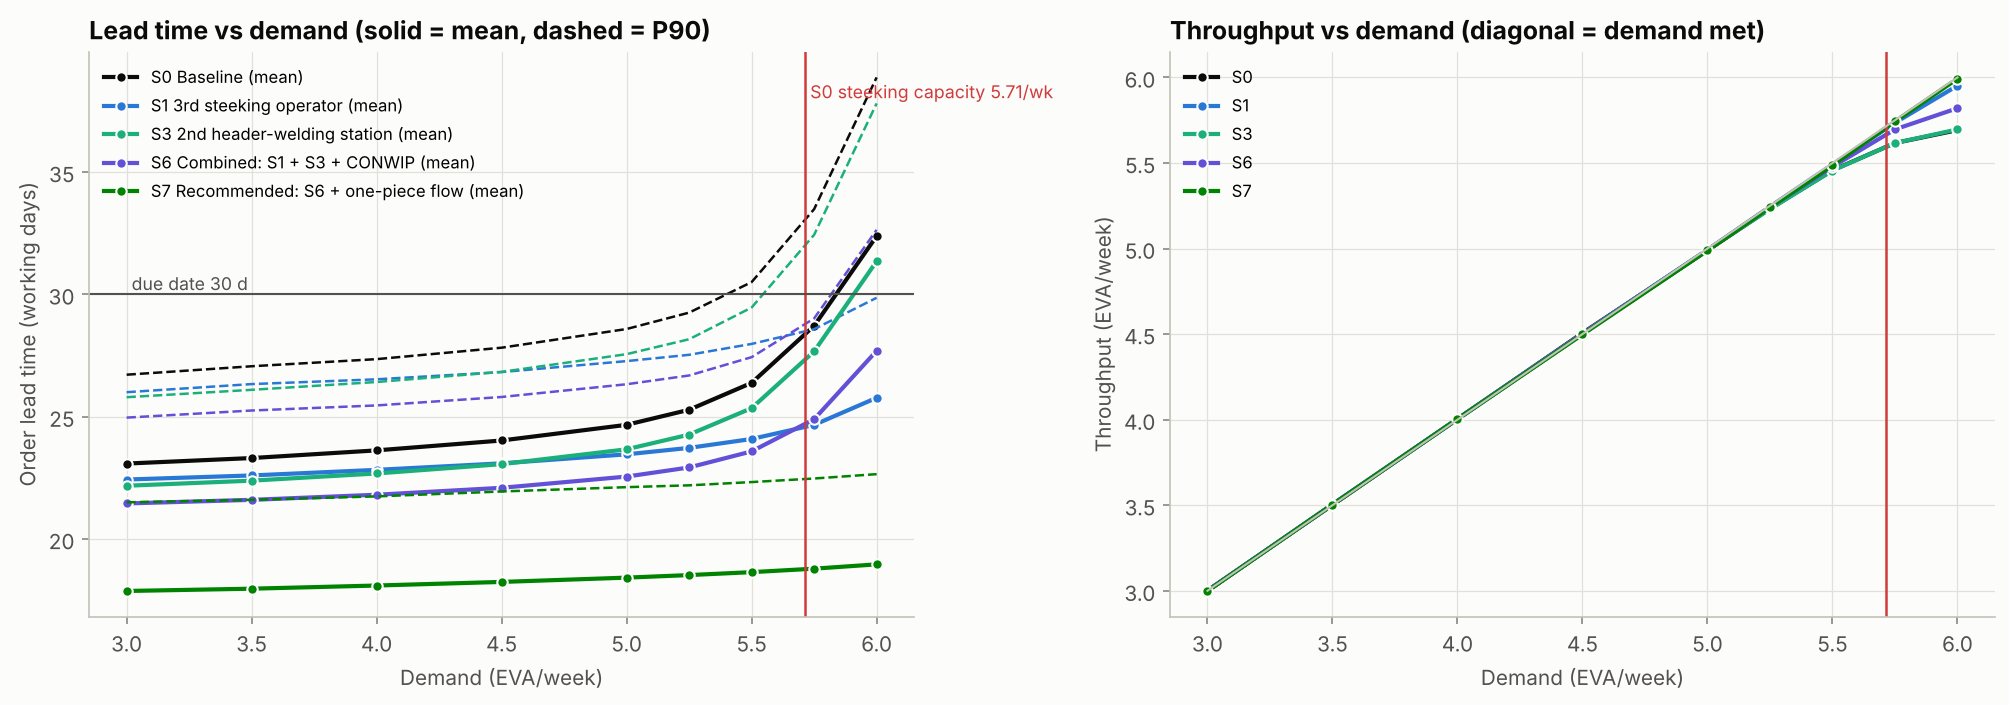

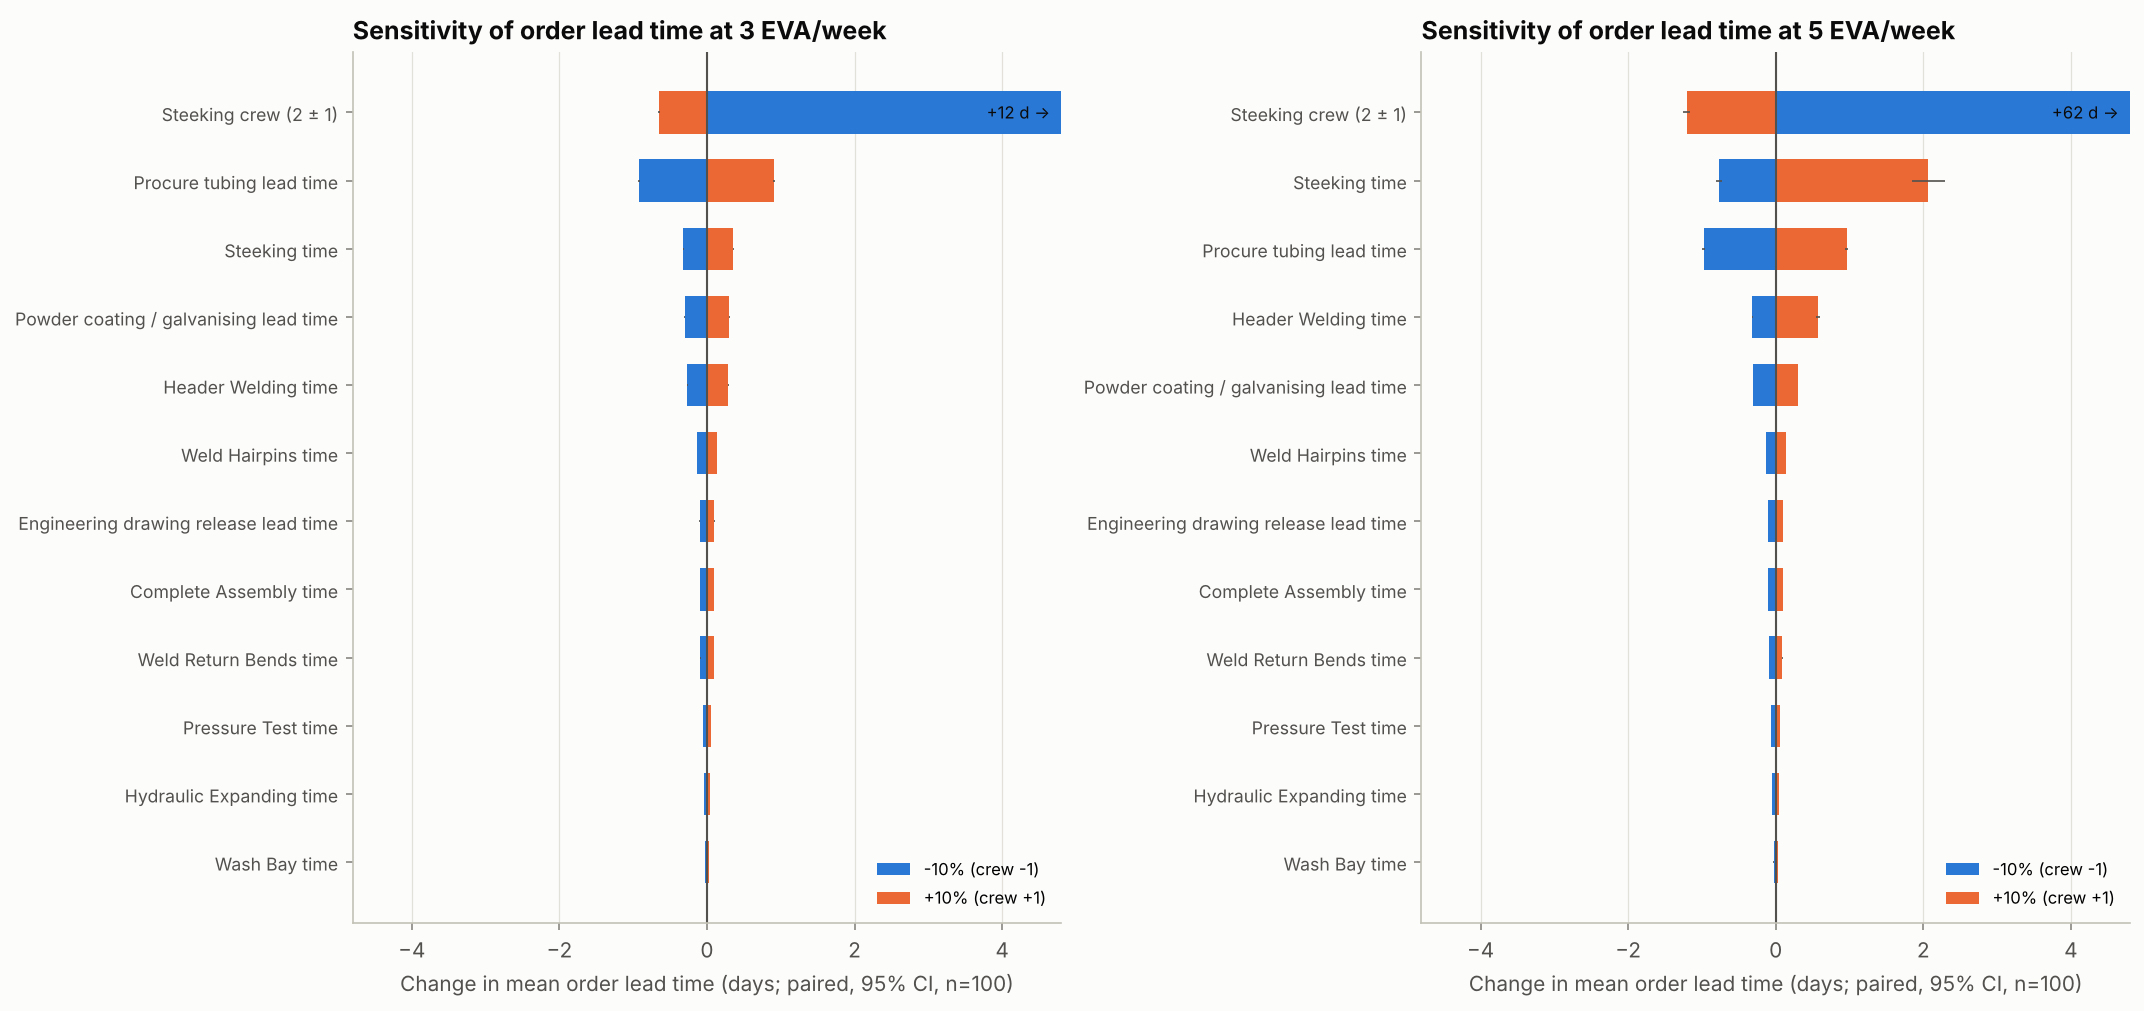

In [12]:
for f in ("scenario_comparison.png", "demand_curve.png", "sensitivity_tornado.png"):
    display(Image(filename=str(FIG / f), width=1000))

## 8. Value stream maps

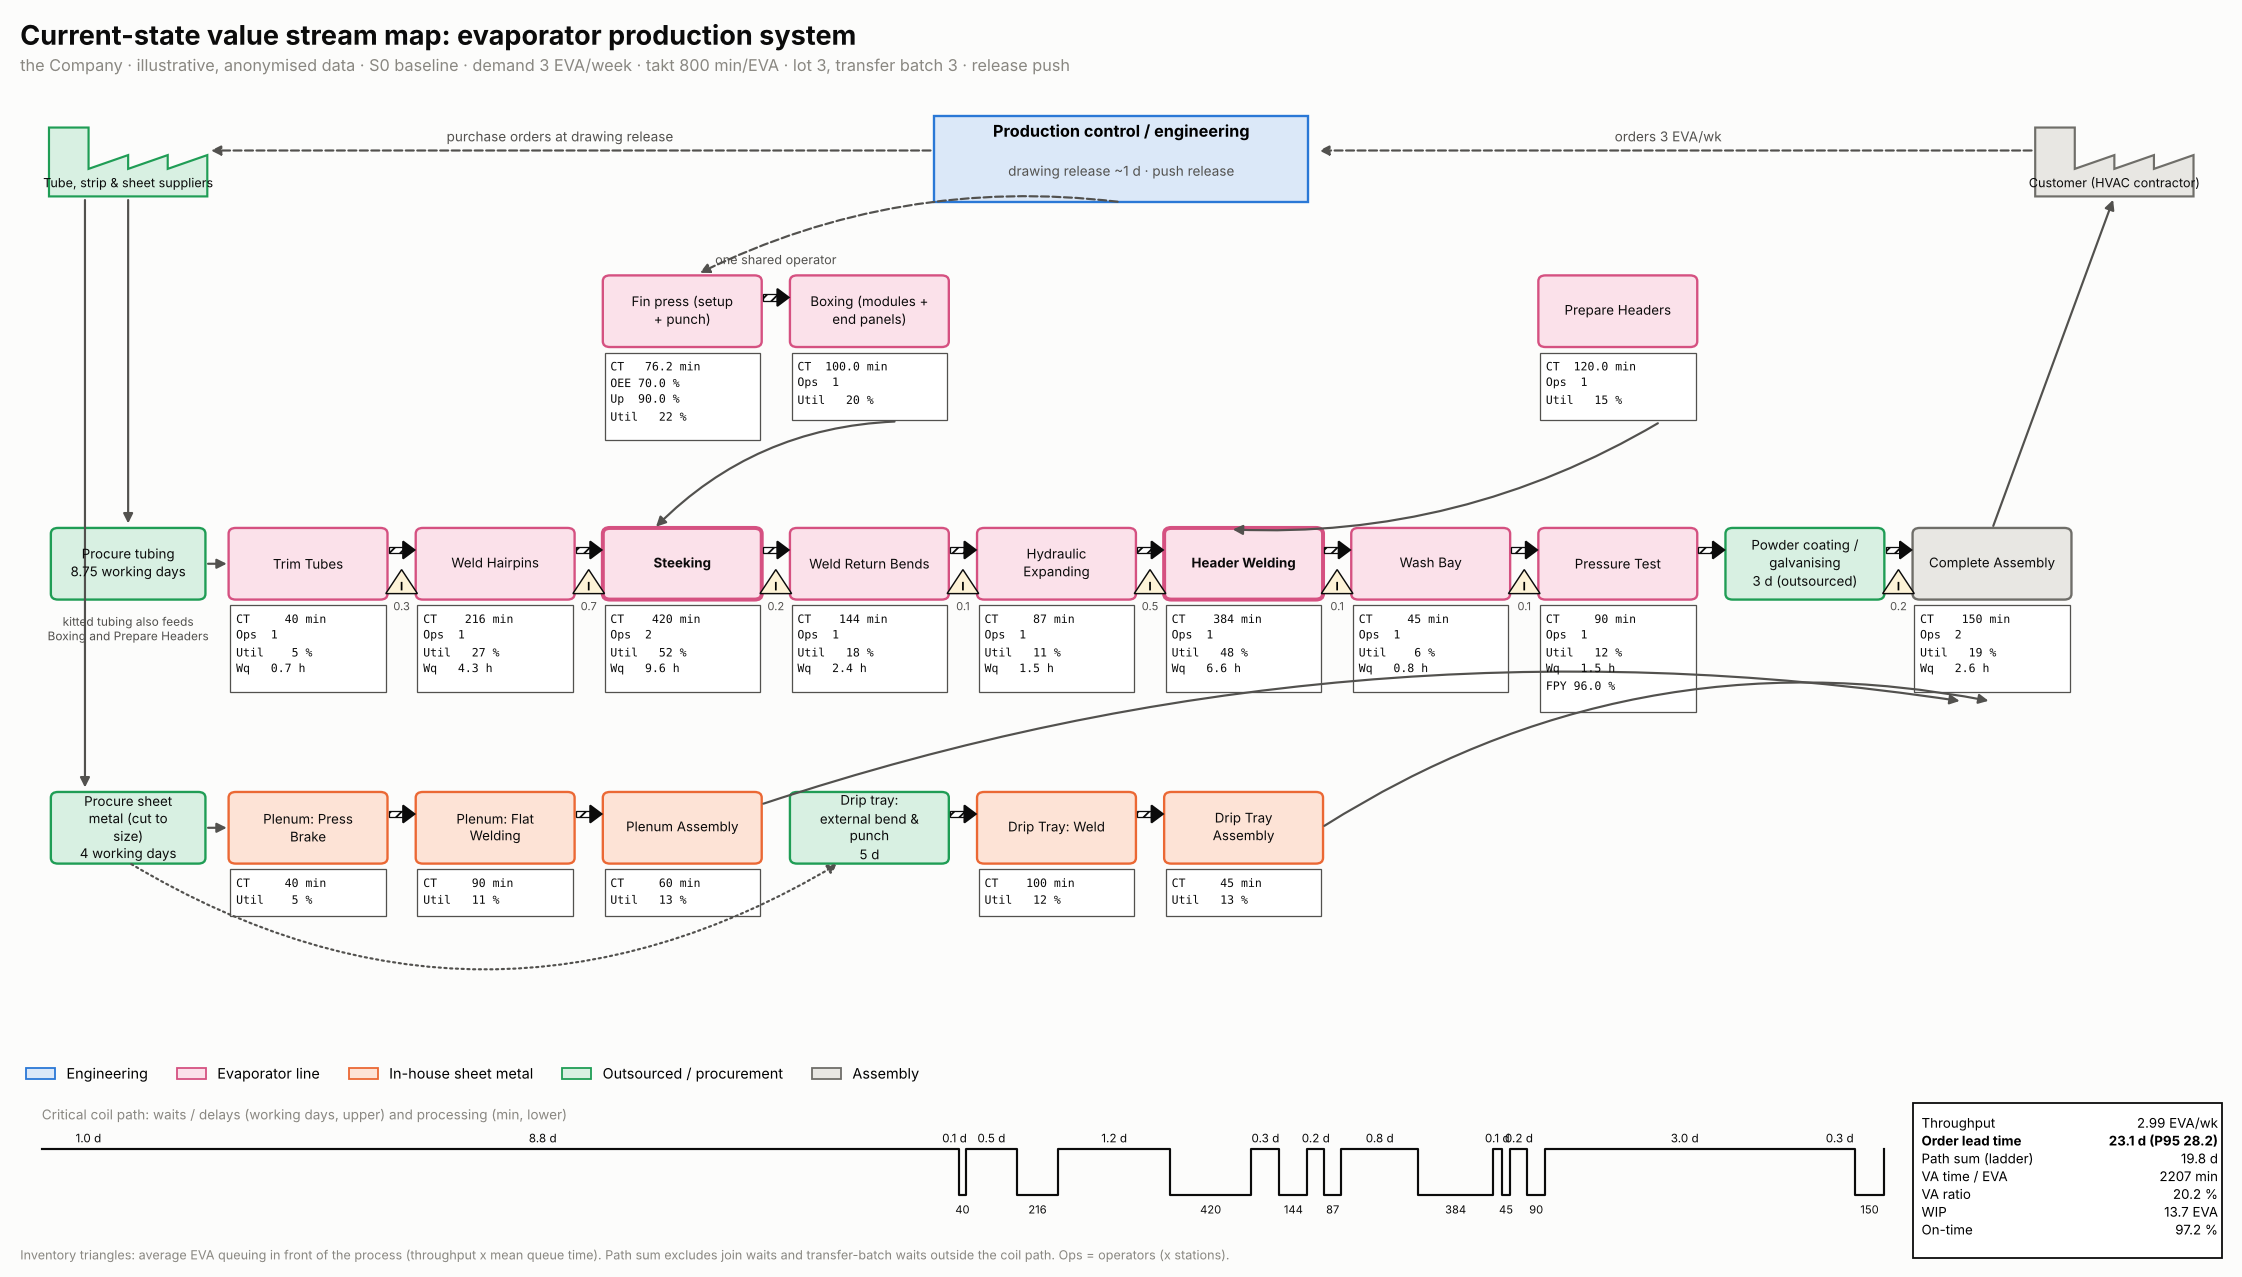

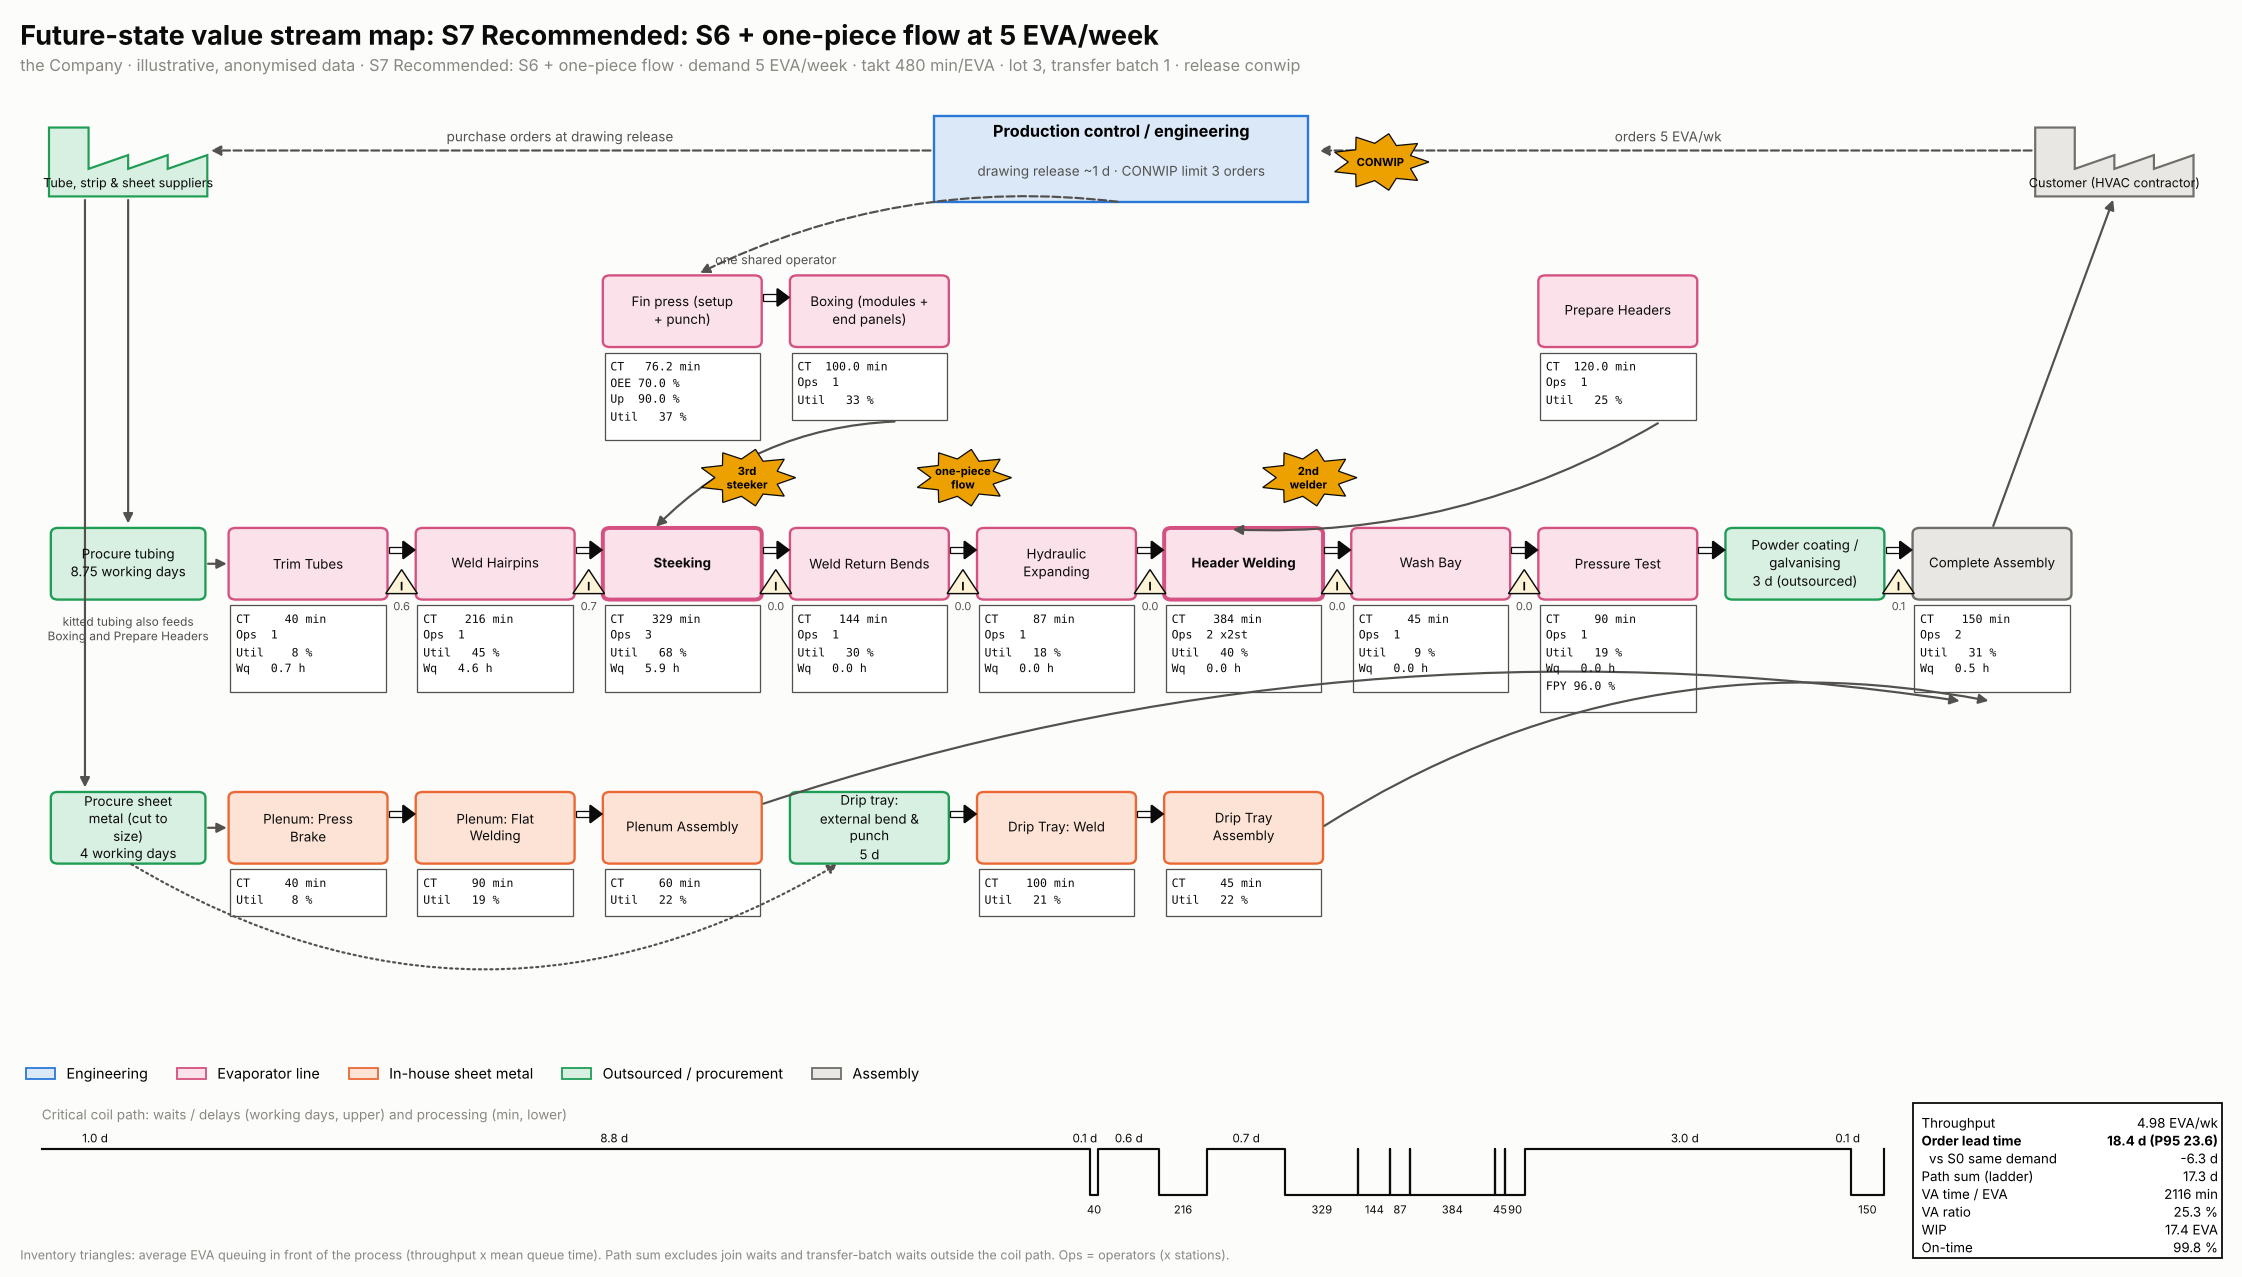

,state,label,demand_eva_per_week,throughput_eva_week,order_lead_time_days,order_lead_time_p95_days,eva_lead_time_days,va_min_per_eva,va_ratio,wip_eva,on_time,steeking_queue_h,header_queue_h
0,current,S0 baseline,3.0,2.992,23.122,28.242,22.810,2207.314,0.202,13.655,0.972,9.564,6.627
1,S0 at future demand,S0 @ 5,5.0,4.979,24.722,30.100,24.409,2206.972,0.188,24.363,0.942,20.150,7.199
2,future,S7 Recommended: S6 + one-piece flow,5.0,4.984,18.446,23.603,17.445,2116.414,0.253,17.409,0.998,5.879,0.007


In [13]:
display(Image(filename=str(ROOT / "docs" / "vsm_current.png"), width=1100))
display(Image(filename=str(ROOT / "docs" / "vsm_future.png"), width=1100))
pd.read_csv(RES / "vsm_summary.csv").round(3)

## 9. Conclusions (computed from the result files)

In [14]:
p = pd.read_csv(RES / "scenario_paired_differences.csv")
lt = p[p.metric == "lt_mean_days"].set_index(["scenario", "demand_eva_per_week"])
s2 = s.set_index(["scenario", "demand_eva_per_week"])
sw = pd.read_csv(RES / "demand_sweep.csv")
s0 = sw[sw.scenario == "S0"].set_index("demand_eva_per_week")
for d in (3.0, 5.0):
    best = lt.xs(d, level=1)["diff_mean"].idxmin()
    print(f"@ {d:g} EVA/wk: S0 LT {s2.loc[('S0', d), 'lt_mean_days_mean']:.1f} d; best {best} "
          f"{lt.loc[(best, d), 'diff_mean']:+.2f} d ({lt.loc[(best, d), 'rel_change_pct']:+.1f} %)")
print("S1 moves the bottleneck to:", s2.loc[("S1", 5.0), "bottleneck"])
print("S4 (fin press OEE 85%) lead-time effect:", round(lt.loc[("S4", 5.0), "diff_mean"], 3), "d")
knee = s0[s0.throughput_eva_week_mean < s0.index * 0.99].index.min()
print(f"S0 lead time: {s0.loc[5.0, 'lt_mean_days_mean']:.1f} d at 5, {s0.loc[5.5, 'lt_mean_days_mean']:.1f} at 5.5, "
      f"{s0.loc[6.0, 'lt_mean_days_mean']:.1f} at 6 EVA/wk; throughput falls below demand from {knee:g} EVA/wk")

@ 3 EVA/wk: S0 LT 23.1 d; best S7 -5.24 d (-22.7 %)
@ 5 EVA/wk: S0 LT 24.7 d; best S7 -6.28 d (-25.4 %)
S1 moves the bottleneck to: header_welder
S4 (fin press OEE 85%) lead-time effect: 0.0 d
S0 lead time: 24.7 d at 5, 26.4 at 5.5, 32.4 at 6 EVA/wk; throughput falls below demand from 5.75 EVA/wk
